# Pipeline de Ciência de Dados — Heart Failure Prediction

**Integrantes:** Pedro Lucas Francisco, Nathalia Rodrigues e Pedro Henrique Cavalcante

Objetivo: prever a presença de doença cardíaca (`HeartDisease`) a partir de dados clínicos.
Etapas: pré-processamento, engenharia de atributos, redução de dimensionalidade (Rank/PCA),
modelagem, avaliação, otimização de hiperparâmetros e exportação do modelo para a API.

## 0. Bibliotecas e configuração

In [1]:
import sys, os, json, warnings, functools
sys.path.append(os.path.abspath(".."))   # permite importar src.features
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn, joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

from src.features import preparar, NUMERICAS, CATEGORICAS, COLUNAS_ENTRADA

SEED = 42
sns.set_theme(style="whitegrid")
os.makedirs("../relatorio/figuras", exist_ok=True)
os.makedirs("../models", exist_ok=True)

def salvar(nome):
    plt.savefig(f"../relatorio/figuras/{nome}.png", dpi=150, bbox_inches="tight")

versoes = pd.DataFrame({
    "biblioteca": ["python", "pandas", "numpy", "scikit-learn", "matplotlib", "seaborn", "joblib"],
    "versao": [sys.version.split()[0], pd.__version__, np.__version__, sklearn.__version__,
               plt.matplotlib.__version__, sns.__version__, joblib.__version__],
})
versoes

,biblioteca,versao
0,python,3.12.10
1,pandas,3.1.1
2,numpy,2.5.5
3,scikit-learn,1.9.1
4,matplotlib,3.11.2
5,seaborn,0.13.2
6,joblib,1.6.0


## 1. Dados

In [2]:
df = pd.read_csv("../data/heart.csv")
print("Formato:", df.shape)
df.head()

Formato: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
print(df.dtypes)
print("\nDuplicatas:", df.duplicated().sum())
print("Cholesterol == 0:", (df["Cholesterol"] == 0).sum(), "| RestingBP == 0:", (df["RestingBP"] == 0).sum())
print("\nBalanceamento do alvo:")
print(df["HeartDisease"].value_counts(normalize=True).round(3))
df.describe().T

Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object

Duplicatas: 0
Cholesterol == 0: 172 | RestingBP == 0: 1

Balanceamento do alvo:
HeartDisease
1    0.553
0    0.447
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


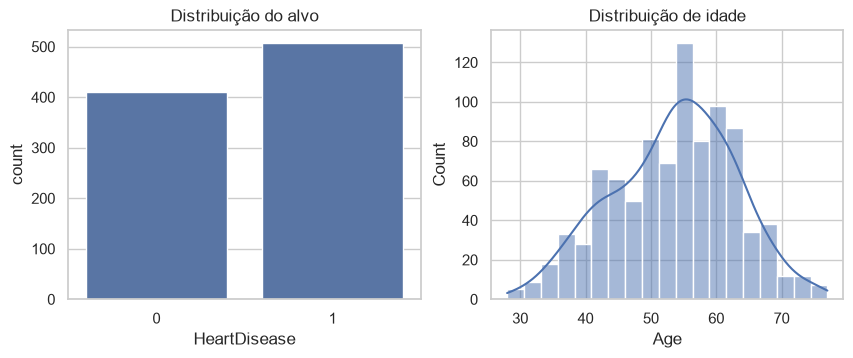

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
sns.countplot(x="HeartDisease", data=df, ax=ax[0]); ax[0].set_title("Distribuição do alvo")
sns.histplot(df["Age"], kde=True, ax=ax[1]); ax[1].set_title("Distribuição de idade")
salvar("01_distribuicao_alvo_idade")
plt.show()

## 2. Pré-processamento

- Remoção de registros duplicados.
- Valores `0` em `Cholesterol` e `RestingBP` são fisiologicamente impossíveis: tratados como ausentes
  (função `preparar`, em `src/features.py`).
- Imputação pela **mediana**, padronização (`StandardScaler`) das numéricas e `OneHotEncoder` das categóricas.
- Todas essas etapas ficam **dentro do Pipeline** e são ajustadas só com os dados de treino, evitando vazamento de dados.
- Divisão treino/teste 80/20, estratificada pelo alvo.

In [5]:
df = df.drop_duplicates().reset_index(drop=True)
X = df[COLUNAS_ENTRADA]
y = df["HeartDisease"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print("Ausentes após tratar zeros:")
print(preparar(X_train).isna().sum()[lambda s: s > 0])

Treino: (734, 11) | Teste: (184, 11)
Ausentes após tratar zeros:
Cholesterol    129
dtype: int64


## 3. Engenharia de atributos

Três atributos novos, criados em `preparar`:

| Atributo | Descrição |
|---|---|
| `FaixaEtaria` | faixa etária (até 40, 41–50, 51–60, acima de 60) |
| `MaxHR_pct` | frequência cardíaca máxima atingida / FC máxima teórica (220 − idade) |
| `ColesterolAlto` | 1 se colesterol ≥ 240 mg/dl, senão 0 |

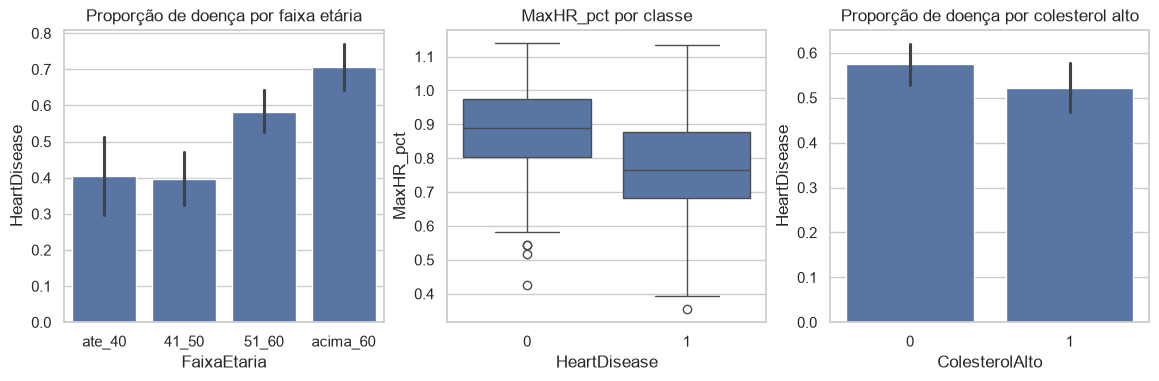

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,FaixaEtaria,MaxHR_pct,ColesterolAlto,HeartDisease
485,63,M,ATA,139,217.0,1,ST,128,Y,1.2,Flat,acima_60,0.815287,0,1
486,55,M,ATA,110,214.0,1,ST,180,N,0.4,Up,51_60,1.090909,0,0
117,59,F,ASY,130,338.0,1,ST,130,Y,1.5,Flat,51_60,0.807453,1,1
361,47,M,ASY,160,NaN,0,Normal,124,Y,0.0,Flat,41_50,0.716763,0,1
296,50,M,ASY,145,NaN,1,Normal,139,Y,0.7,Flat,41_50,0.817647,0,1


In [6]:
amostra = preparar(X_train).assign(HeartDisease=y_train.values)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
sns.barplot(x="FaixaEtaria", y="HeartDisease", data=amostra, order=["ate_40", "41_50", "51_60", "acima_60"], ax=ax[0])
sns.boxplot(x="HeartDisease", y="MaxHR_pct", data=amostra, ax=ax[1])
sns.barplot(x="ColesterolAlto", y="HeartDisease", data=amostra, ax=ax[2])
ax[0].set_title("Proporção de doença por faixa etária")
ax[1].set_title("MaxHR_pct por classe")
ax[2].set_title("Proporção de doença por colesterol alto")
salvar("02_novos_atributos")
plt.show()
amostra.head()

## 4. Construção do pipeline

In [7]:
def construir_pipeline(modelo, k="all"):
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUMERICAS),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAS),
    ])
    selecao = SelectKBest(functools.partial(mutual_info_classif, random_state=SEED), k=k)
    return Pipeline([
        ("prep", FunctionTransformer(preparar)),   # limpeza + novos atributos
        ("pre", pre),                              # imputação, escala, one-hot
        ("sel", selecao),                          # Rank por informação mútua
        ("modelo", modelo),
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
metricas = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

## 5. Redução de dimensionalidade: Rank e PCA

Aplicamos as duas técnicas. O **Rank** (informação mútua entre cada atributo e o alvo, via `SelectKBest`) é usado
no pipeline final por manter os atributos originais e, portanto, o modelo interpretável.
O **PCA** é usado para comparação.

In [8]:
prep_only = construir_pipeline(LogisticRegression()).steps[:2]
prep_only = Pipeline(prep_only)
Xt = prep_only.fit_transform(X_train)
nomes = prep_only.named_steps["pre"].get_feature_names_out()
print("Atributos após pré-processamento:", Xt.shape[1])

mi = mutual_info_classif(Xt, y_train, random_state=SEED)
rf_imp = RandomForestClassifier(n_estimators=300, random_state=SEED).fit(Xt, y_train).feature_importances_
rank = (pd.DataFrame({"atributo": nomes, "info_mutua": mi, "importancia_rf": rf_imp})
        .sort_values("info_mutua", ascending=False).reset_index(drop=True))
rank.to_csv("../models/rank_atributos.csv", index=False)
rank

Atributos após pré-processamento: 26


,atributo,info_mutua,importancia_rf
0,cat__ST_Slope_Up,0.228640,0.152427
1,cat__ST_Slope_Flat,0.162433,0.103376
2,cat__ChestPainType_ASY,0.143078,0.079176
3,cat__ExerciseAngina_N,0.135980,0.052118
4,cat__ExerciseAngina_Y,0.122721,0.046751
5,num__Oldpeak,0.107920,0.076765
6,num__MaxHR,0.095980,0.070654
7,cat__ChestPainType_ATA,0.092673,0.022498
8,num__Cholesterol,0.072817,0.058027
9,num__MaxHR_pct,0.066009,0.079410


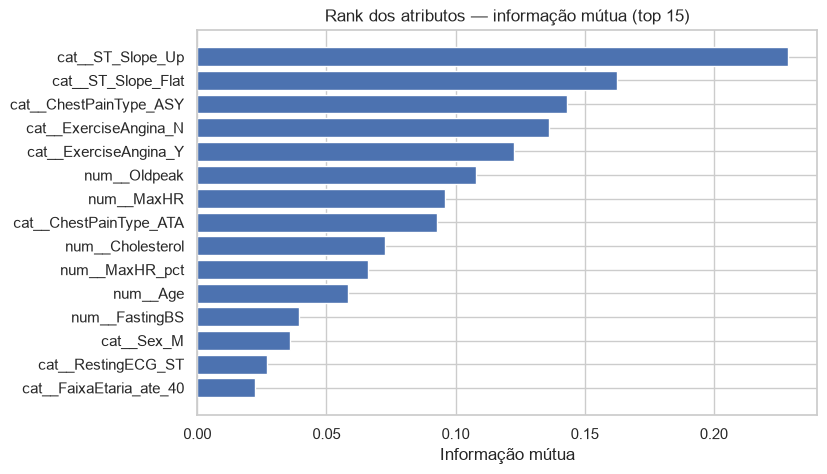

In [9]:
top = rank.head(15).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top["atributo"], top["info_mutua"])
plt.title("Rank dos atributos — informação mútua (top 15)")
plt.xlabel("Informação mútua")
salvar("03_rank_atributos")
plt.show()

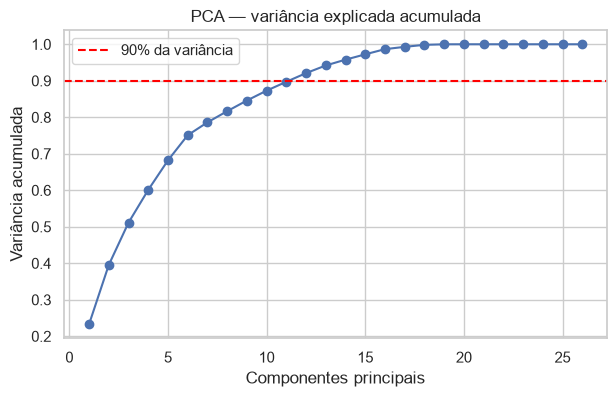

Componentes para 90% da variância: 12 de 26


In [10]:
pca = PCA().fit(Xt)
var_acum = np.cumsum(pca.explained_variance_ratio_)
n90 = int(np.argmax(var_acum >= 0.90) + 1)
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(var_acum) + 1), var_acum, marker="o")
plt.axhline(0.90, color="red", ls="--", label="90% da variância")
plt.xlabel("Componentes principais"); plt.ylabel("Variância acumulada"); plt.legend()
plt.title("PCA — variância explicada acumulada")
salvar("04_pca_variancia")
plt.show()
print(f"Componentes para 90% da variância: {n90} de {Xt.shape[1]}")

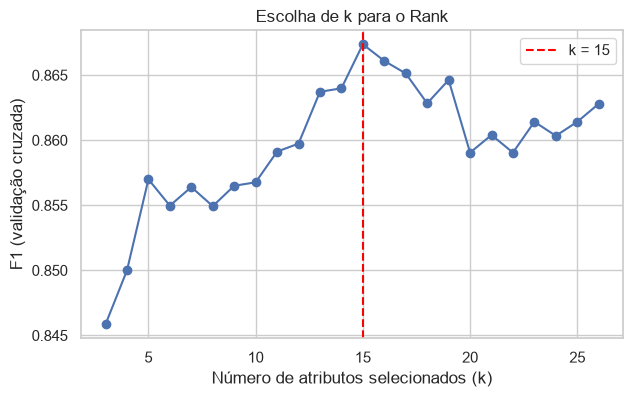

Melhor k: 15 | F1 CV: 0.8674
Atributos selecionados: ['cat__ST_Slope_Up', 'cat__ST_Slope_Flat', 'cat__ChestPainType_ASY', 'cat__ExerciseAngina_N', 'cat__ExerciseAngina_Y', 'num__Oldpeak', 'num__MaxHR', 'cat__ChestPainType_ATA', 'num__Cholesterol', 'num__MaxHR_pct', 'num__Age', 'num__FastingBS', 'cat__Sex_M', 'cat__RestingECG_ST', 'cat__FaixaEtaria_ate_40']


In [11]:
# Escolha do número de atributos (k) do Rank por validação cruzada (regressão logística, F1)
ks = list(range(3, Xt.shape[1] + 1))
f1_por_k = []
for k in ks:
    s = cross_validate(construir_pipeline(LogisticRegression(max_iter=1000), k=k), X_train, y_train, cv=cv, scoring="f1")
    f1_por_k.append(s["test_score"].mean())
melhor_k = ks[int(np.argmax(f1_por_k))]
plt.figure(figsize=(7, 4))
plt.plot(ks, f1_por_k, marker="o"); plt.axvline(melhor_k, color="red", ls="--", label=f"k = {melhor_k}")
plt.xlabel("Número de atributos selecionados (k)"); plt.ylabel("F1 (validação cruzada)"); plt.legend()
plt.title("Escolha de k para o Rank")
salvar("05_escolha_k")
plt.show()
print("Melhor k:", melhor_k, "| F1 CV:", round(max(f1_por_k), 4))
print("Atributos selecionados:", list(rank["atributo"].head(melhor_k)))

## 6. Modelos e métricas

Três algoritmos com hiperparâmetros **padrão**, avaliados por validação cruzada estratificada (5 folds)
no conjunto de treino e, depois, no conjunto de teste. Como o contexto é médico, damos atenção especial ao
**recall** (não deixar de detectar pacientes doentes), mas o critério de escolha é o **F1**.

In [12]:
modelos = {
    "Regressão Logística": LogisticRegression(max_iter=1000, random_state=SEED),
    "Random Forest": RandomForestClassifier(random_state=SEED),
    "KNN": KNeighborsClassifier(),
}
linhas = []
for nome, m in modelos.items():
    s = cross_validate(construir_pipeline(m, k=melhor_k), X_train, y_train, cv=cv, scoring=metricas)
    linhas.append({"modelo": nome, **{k: s[f"test_{k}"].mean() for k in metricas}})
cv_tab = pd.DataFrame(linhas).set_index("modelo").round(4)
cv_tab.to_csv("../models/metricas_cv_modelos_padrao.csv")
cv_tab

,accuracy,precision,recall,f1,roc_auc
modelo,,,,,
Regressão Logística,0.8515,0.8620,0.8745,0.8674,0.9201
Random Forest,0.8488,0.8613,0.8696,0.8642,0.9229
KNN,0.8392,0.8509,0.8622,0.8559,0.8934


In [13]:
melhor_nome = cv_tab["f1"].idxmax()
print("Modelo escolhido (maior F1 na validação cruzada):", melhor_nome)

teste_linhas, ajustados = [], {}
for nome, m in modelos.items():
    p = construir_pipeline(m, k=melhor_k).fit(X_train, y_train)
    ajustados[nome] = p
    pred, proba = p.predict(X_test), p.predict_proba(X_test)[:, 1]
    teste_linhas.append({"modelo": nome, "accuracy": accuracy_score(y_test, pred),
                         "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
                         "f1": f1_score(y_test, pred), "roc_auc": roc_auc_score(y_test, proba)})
teste_tab = pd.DataFrame(teste_linhas).set_index("modelo").round(4)
teste_tab.to_csv("../models/metricas_teste_modelos_padrao.csv")
teste_tab

Modelo escolhido (maior F1 na validação cruzada): Regressão Logística


,accuracy,precision,recall,f1,roc_auc
modelo,,,,,
Regressão Logística,0.8967,0.9029,0.9118,0.9073,0.9365
Random Forest,0.8533,0.8641,0.8725,0.8683,0.9198
KNN,0.8370,0.8396,0.8725,0.8558,0.9014


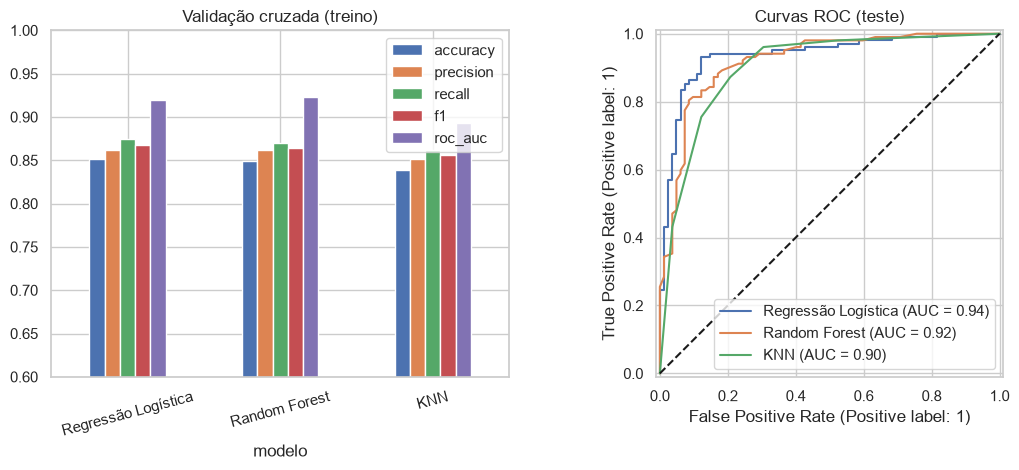

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
cv_tab.plot.bar(ax=ax[0], rot=15); ax[0].set_title("Validação cruzada (treino)"); ax[0].set_ylim(0.6, 1)
for nome, p in ajustados.items():
    RocCurveDisplay.from_estimator(p, X_test, y_test, name=nome, ax=ax[1])
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title("Curvas ROC (teste)")
salvar("06_comparacao_modelos")
plt.show()

## 7. Otimização de hiperparâmetros

Biblioteca: **scikit-learn** — `GridSearchCV` (busca em grade com validação cruzada estratificada de 5 folds,
métrica de otimização F1, `random_state = 42`). A busca é feita **somente** no treino; o teste só é usado
na comparação final.

In [15]:
espacos = {
    "Regressão Logística": {
        "modelo__C": [0.01, 0.1, 1, 10, 100],
        "modelo__class_weight": [None, "balanced"],
        "sel__k": [melhor_k, "all"],
    },
    "Random Forest": {
        "modelo__n_estimators": [100, 200, 300],
        "modelo__max_depth": [None, 5, 10],
        "modelo__min_samples_split": [2, 5, 10],
        "modelo__min_samples_leaf": [1, 2],
        "sel__k": [melhor_k, "all"],
    },
    "KNN": {
        "modelo__n_neighbors": [3, 5, 7, 9, 11, 15],
        "modelo__weights": ["uniform", "distance"],
        "modelo__p": [1, 2],
        "sel__k": [melhor_k, "all"],
    },
}
grade = GridSearchCV(construir_pipeline(modelos[melhor_nome], k=melhor_k), espacos[melhor_nome],
                     scoring="f1", cv=cv, n_jobs=-1, refit=True)
grade.fit(X_train, y_train)
print("Melhores hiperparâmetros:", grade.best_params_)
print("Melhor F1 (CV):", round(grade.best_score_, 4))

Melhores hiperparâmetros: {'modelo__C': 0.1, 'modelo__class_weight': None, 'sel__k': 'all'}
Melhor F1 (CV): 0.8685


In [16]:
padrao = ajustados[melhor_nome]
otimizado = grade.best_estimator_

def avaliar(p):
    pred, proba = p.predict(X_test), p.predict_proba(X_test)[:, 1]
    return {"accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred),
            "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred),
            "roc_auc": roc_auc_score(y_test, proba)}

comp = pd.DataFrame({"padrão": avaliar(padrao), "otimizado": avaliar(otimizado)}).T.round(4)
comp.to_csv("../models/comparacao_padrao_vs_otimizado.csv")
comp

,accuracy,precision,recall,f1,roc_auc
padrão,0.8967,0.9029,0.9118,0.9073,0.9365
otimizado,0.8967,0.8952,0.9216,0.9082,0.9338


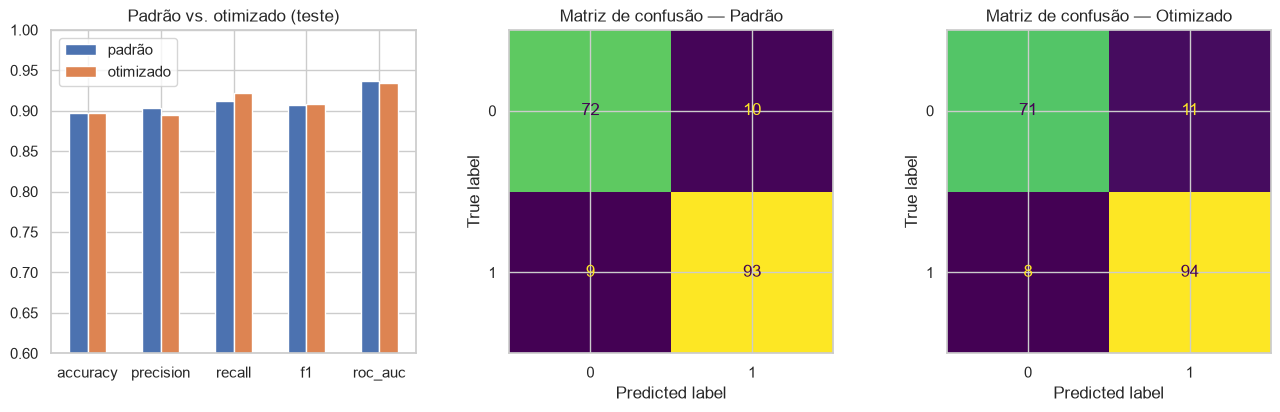

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
comp.T.plot.bar(ax=ax[0], rot=0); ax[0].set_ylim(0.6, 1); ax[0].set_title("Padrão vs. otimizado (teste)")
for a, (nome, p) in zip(ax[1:], [("Padrão", padrao), ("Otimizado", otimizado)]):
    ConfusionMatrixDisplay.from_predictions(y_test, p.predict(X_test), ax=a, colorbar=False)
    a.set_title(f"Matriz de confusão — {nome}")
salvar("07_padrao_vs_otimizado")
plt.show()

In [18]:
# Relatório de hiperparâmetros (para a seção Material e Métodos / Resultados)
padrao_params = modelos[melhor_nome].get_params()
linhas = [{"hiperparametro": "k (Rank, SelectKBest)", "espaco_testado": str(espacos[melhor_nome]["sel__k"]),
           "valor_padrao": melhor_k, "valor_escolhido": grade.best_params_["sel__k"]}]
for chave, valores in espacos[melhor_nome].items():
    if chave.startswith("modelo__"):
        nome_hp = chave.split("__", 1)[1]
        linhas.append({"hiperparametro": nome_hp, "espaco_testado": str(valores),
                       "valor_padrao": padrao_params.get(nome_hp), "valor_escolhido": grade.best_params_[chave]})
hp_tab = pd.DataFrame(linhas)
hp_tab.to_csv("../models/relatorio_hiperparametros.csv", index=False)

relatorio = {
    "modelo_escolhido": melhor_nome,
    "biblioteca_otimizacao": f"scikit-learn {sklearn.__version__} (GridSearchCV)",
    "validacao_cruzada": "StratifiedKFold, 5 folds, shuffle, random_state=42",
    "metrica_otimizacao": "f1",
    "melhor_f1_cv": round(float(grade.best_score_), 4),
    "melhores_hiperparametros": {k: (v if isinstance(v, (int, float, str, type(None))) else str(v))
                                 for k, v in grade.best_params_.items()},
    "metricas_teste_padrao": {k: round(v, 4) for k, v in avaliar(padrao).items()},
    "metricas_teste_otimizado": {k: round(v, 4) for k, v in avaliar(otimizado).items()},
    "bibliotecas": versoes.set_index("biblioteca")["versao"].to_dict(),
}
with open("../models/relatorio_hiperparametros.json", "w", encoding="utf-8") as f:
    json.dump(relatorio, f, ensure_ascii=False, indent=2)
hp_tab

,hiperparametro,espaco_testado,valor_padrao,valor_escolhido
0,"k (Rank, SelectKBest)","[15, 'all']",15.0,all
1,C,"[0.01, 0.1, 1, 10, 100]",1.0,0.1
2,class_weight,"[None, 'balanced']",NaN,None


## 8. Exportação do modelo para produção

O pipeline completo (limpeza, novos atributos, pré-processamento, seleção Rank e modelo) é salvo em
`models/modelo.joblib` e carregado pela API (`api/main.py`), que recebe os 11 atributos originais do paciente.

In [19]:
joblib.dump(otimizado, "../models/modelo.joblib")
with open("../models/metadata.json", "w", encoding="utf-8") as f:
    json.dump({"modelo": melhor_nome, "sklearn": sklearn.__version__, "k_rank": int(melhor_k),
               "metricas_teste": relatorio["metricas_teste_otimizado"]}, f, ensure_ascii=False, indent=2)

# Teste de sanidade: recarrega o modelo e prevê um paciente com os atributos originais
modelo_prod = joblib.load("../models/modelo.joblib")
paciente = pd.DataFrame([{"Age": 58, "Sex": "M", "ChestPainType": "ASY", "RestingBP": 140, "Cholesterol": 0,
                          "FastingBS": 1, "RestingECG": "Normal", "MaxHR": 110, "ExerciseAngina": "Y",
                          "Oldpeak": 1.5, "ST_Slope": "Flat"}])
print("Classe prevista:", int(modelo_prod.predict(paciente)[0]),
      "| Probabilidade de doença:", round(float(modelo_prod.predict_proba(paciente)[0, 1]), 3))

Classe prevista: 1 | Probabilidade de doença: 0.977


## 9. Conclusão

Os resultados, tabelas e figuras gerados aqui (`models/` e `relatorio/figuras/`) alimentam o relatório.
Aviso: projeto acadêmico, sem validade para uso clínico.